# Drift: the PSI rules, their benchmark and the false-alarm rate

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the rate and the size of every test)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- compute the population stability index (PSI) of two binned samples with the engine, read its band, its chi-square p-value and its 5% benchmark, and say how they differ;
- state the sampling distribution of the PSI under no change, $(1/n + 1/m)^{-1}\,\mathrm{PSI} \approx \chi^2_{B-1}$, and use it to explain why the 0.10 and 0.25 rules of thumb have uncontrolled error rates that depend on the sample sizes;
- measure the false-alarm rate of the two rules and the power of the benchmark, the chi-square and the Kolmogorov-Smirnov tests along a ladder of mean shifts, and replay a committed row from its seed;
- recompute the cells of Yurdakul and Naranjo's Table 4 against the committed reproduction (50 of 54) and read the four that differ;
- say why a drifted population does not make a right model miscalibrated, and what that means for the alarm a validator should raise.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `drift` family of case C22 (validating the validator). Its `stability` panel draws two samples of one variable following the design of Yurdakul and Naranjo (2020): a base sample from $N(0, 8^2)$, binned in its ten population deciles, and a target sample from $N(\mu, 8^2)$ with $\mu$ a fraction of a standard deviation on the ladder 0, 0.05, 0.1, 0.2, 0.3 and 0.5. Its `calibration` panel draws a logistic portfolio whose covariates are shifted by the same amount while the model stays exactly right. Every dataset comes from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`); the published rates are quoted from the paper (derived-only, as numbers).

- **File read:** `data/derived/C22/drift.json`: `outputs.simulations` (30 rows, 2,000 repetitions each, samples of 1,000), `outputs.golden` (the 54 cells of Table 4 of Yurdakul and Naranjo with the published and the measured rate), `outputs.generators` and `impact`. The family's samples of 100 sit in the `null` family (`stability.psi@n100`), read from `data/derived/C22/null.json` in notebook 02 and replayed here from its seed.
- **Rules:** the rows of `stability.psi` carry four decision rules: `p<0.05` and `p<0.01` (the chi-square benchmark) and the two rules of thumb, `metric>0.1` and `metric>0.25`.

The next cell loads the artifact and prints the ladder, the panels and the rule labels.

In [2]:
# Load the drift family, index its rows and print the ladder, the panels and the decision rules of the PSI rows
LANG = "en"
ROOT = Path("../../..").resolve()
drift = json.loads((ROOT / "data" / "derived" / "C22" / "drift.json").read_text(encoding="utf-8"))
out = drift["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]

print("baked by riskvalidation", drift["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)
print("ladder:", out["ladder"]["label"][LANG], ladder)
measure_name = {"size": "size", "power": "power"}
for panel in out["panels"]:
    print(f"{panel['label'][LANG]:30s} {sum(1 for r in rows.values() if r['panel'] == panel['id'])} rows | measures: {measure_name[panel['measures']]}")
print("decision rules of a PSI row:", list(rows["stability.psi@s0.1"]["rates"]))

baked by riskvalidation 0.4.3 | installed 0.8.1
ladder: mean shift (standard deviations) [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
Stability                      18 rows | measures: power
Calibration                    12 rows | measures: size
decision rules of a PSI row: ['p<0.05', 'p<0.01', 'metric>0.1', 'metric>0.25']


## Method

**The PSI.** With $B$ fixed bins, development proportions $e_i$ and current proportions $a_i$, the index is

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

the symmetrised Kullback-Leibler divergence. Practice reads it against two rules of thumb, 0.10 (little change below) and 0.25 (significant change above), "used without reference to statistical type I or type II error rates" (Yurdakul and Naranjo, 2020).

**Its sampling distribution.** For base and target samples of $n$ and $m$ observations on fixed bins, Theorem 3.3 of the paper gives, under no change,

$$\Big(\tfrac1n + \tfrac1m\Big)^{-1}\,\mathrm{PSI} \;\approx\; \chi^2_{B-1}, \qquad E[\mathrm{PSI}] \approx \Big(\tfrac1n + \tfrac1m\Big)(B-1)$$

so the PSI carries sampling noise that depends on the sample sizes alone, and the test that controls the type I error rejects when $\mathrm{PSI} > (1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$. The engine's `psi_benchmark` returns that critical value and `stability_psi` reports the matching p-value. A fixed band cannot follow it.

The steps compute the noise floor, the benchmark and a first result, measure the rules' false alarms, the power along the ladder, reproduce the paper's Table 4, and separate drift from miscalibration.

### Step 1: the noise floor of the PSI

The first line of the cell is the expected PSI when nothing changes, $(1/n + 1/m)(B-1)$ with $B = 10$, for four equal sample sizes, next to the 5% benchmark from `psi_benchmark`. With 100 observations per sample the expected PSI under no change already exceeds the 0.10 rule of thumb. The second part computes the population PSI of the shifts of the ladder (no sampling: the PSI of the two populations' decile probabilities that the generator's `truth` carries, through `population_psi`) and compares it with the noise floor of samples of 1,000.

In [3]:
# Expected PSI under no change and the 5% benchmark for four sample sizes, then the population PSI of each shift of the ladder
from riskvalidation.generators import TwoSample, population_psi
from riskvalidation.validation.stability import psi_benchmark

for size in (100, 200, 400, 1000):
    expected_null = (1 / size + 1 / size) * (10 - 1)
    print(f"n = m = {size:4d} | expected PSI under no change {expected_null:.4f} | 5% benchmark {psi_benchmark(size, size):.4f}")

print("population PSI of each shift (no sampling):")
for shift in ladder:
    truth = TwoSample(1000, 1000, shift=shift).truth()
    psi_population = population_psi(truth["bins_base"], truth["bins_target"])
    print(f"  shift {shift:4.2f} | population PSI {psi_population:.4f} | stored in the truth {truth['population_psi']:.4f}")

n = m =  100 | expected PSI under no change 0.1800 | 5% benchmark 0.3384
n = m =  200 | expected PSI under no change 0.0900 | 5% benchmark 0.1692
n = m =  400 | expected PSI under no change 0.0450 | 5% benchmark 0.0846
n = m = 1000 | expected PSI under no change 0.0180 | 5% benchmark 0.0338
population PSI of each shift (no sampling):
  shift 0.00 | population PSI 0.0000 | stored in the truth 0.0000
  shift 0.05 | population PSI 0.0024 | stored in the truth 0.0024
  shift 0.10 | population PSI 0.0096 | stored in the truth 0.0096
  shift 0.20 | population PSI 0.0383 | stored in the truth 0.0383
  shift 0.30 | population PSI 0.0861 | stored in the truth 0.0861
  shift 0.50 | population PSI 0.2377 | stored in the truth 0.2377


### Step 2: where the rules of thumb sit against the benchmark

The 5% benchmark equals a fixed band when $(2/n)\,\chi^2_{0.95,\,9}$ equals the band, which gives the sample size at which the rule and the benchmark agree: below it the rule rejects more often than 5% when nothing changes, above it less. The next cell solves for it with SciPy's chi-square quantile, and prints the benchmark for the six sample-size pairs of Yurdakul and Naranjo's Table 4.

In [4]:
# Sample size at which each rule of thumb equals the 5% benchmark, and the benchmark of the six pairs of Table 4
critical = stats.chi2.ppf(0.95, 9)
for band in (0.10, 0.25):
    print(f"rule of thumb {band:.2f} | equals the 5% benchmark at n = m = {2 * critical / band:.0f}")
for m, n in ((100, 100), (100, 200), (100, 400), (200, 200), (200, 400), (400, 400)):
    print(f"m = {m:3d}, n = {n:3d} | benchmark {psi_benchmark(n, m):.4f}")

rule of thumb 0.10 | equals the 5% benchmark at n = m = 338
rule of thumb 0.25 | equals the 5% benchmark at n = m = 135
m = 100, n = 100 | benchmark 0.3384
m = 100, n = 200 | benchmark 0.2538
m = 100, n = 400 | benchmark 0.2115
m = 200, n = 200 | benchmark 0.1692
m = 200, n = 400 | benchmark 0.1269
m = 400, n = 400 | benchmark 0.0846


### Step 3: three datasets, three readings

`stability_psi` takes the bin counts of the two samples and returns a `TestResult` with the PSI as its metric, the chi-square p-value, the conventional band in its notes, and the 5% benchmark in `extras`. The next cell draws three datasets from the generators and prints what the engine says: samples of 100 with no change, samples of 1,000 with no change, and samples of 1,000 with a shift of 0.2 standard deviations. The band and the p-value need not agree, and that is the point.

In [5]:
# Draw three datasets and read the PSI, its conventional band, its benchmark and its p-value for each
from riskvalidation.validation import stability_psi

cases = (("100 vs 100, no change", TwoSample(100, 100)), ("1000 vs 1000, no change", TwoSample(1000, 1000)),
         ("1000 vs 1000, shift 0.2 SD", TwoSample(1000, 1000, shift=0.2)))
for label, generator in cases:
    sample = generator.draw(np.random.default_rng(31))
    result = stability_psi(sample["expected_counts"], sample["actual_counts"])
    print(f"{label:38s} PSI {result.metric:.4f} | band: {result.extras['band']:20s} | 5% benchmark {result.extras['benchmark_05']:.4f} | p-value {result.p_value:.4f}")

100 vs 100, no change                  PSI 0.2796 | band: significant change   | 5% benchmark 0.3384 | p-value 0.1231
1000 vs 1000, no change                PSI 0.0146 | band: little change        | 5% benchmark 0.0338 | p-value 0.6047
1000 vs 1000, shift 0.2 SD             PSI 0.0392 | band: little change        | 5% benchmark 0.0338 | p-value 0.0205


### Step 4: the false alarms of the two rules, replayed

The `null` family measured the rules on two samples of 100 with nothing changed. The next cell replays that row from its committed seed, with the two rules added exactly as the artifact added them, and compares the counts. It then runs the same experiment for four sample sizes with a new seed and 4,000 repetitions each, to see the error rate of each rule move with the size of the samples: this is the error rate that the paper says no one had stated.

In [6]:
# Replay the committed n = 100 row with its rules, then measure the false-alarm rate of both rules at four sample sizes
from riskvalidation.harness import metric_above, simulate

rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
committed = next(r for r in null["outputs"]["simulations"] if r["key"] == "stability.psi@n100")
replay = simulate("stability.psi", TwoSample(100, 100), n_rep=committed["n_rep"], seed=committed["seed"], rules=rules)
for rule in ("p<0.05", "metric>0.1", "metric>0.25"):
    print(f"{rule:12s} | replay {replay.rates[rule].rejections} | committed {committed['rates'][rule]['rejections']}")

print("false-alarm rate when nothing changed (new seed, 4000 repetitions, ± Monte Carlo SE):")
for size in (100, 200, 400, 1000):
    sim = simulate("stability.psi", TwoSample(size, size), n_rep=4000, seed=2026, rules=rules)
    shown = {name: f"{sim.rates[rule].rate:.3f} ± {sim.rates[rule].se:.3f}" for name, rule in (("a", "metric>0.1"), ("b", "metric>0.25"), ("c", "p<0.05"))}
    print(f"  n = m = {size:4d} | PSI > 0.10: {shown['a']} | PSI > 0.25: {shown['b']} | chi-square benchmark at 5%: {shown['c']}")

p<0.05       | replay 279 | committed 279
metric>0.1   | replay 3399 | committed 3399
metric>0.25  | replay 914 | committed 914
false-alarm rate when nothing changed (new seed, 4000 repetitions, ± Monte Carlo SE):
  n = m =  100 | PSI > 0.10: 0.857 ± 0.006 | PSI > 0.25: 0.227 ± 0.007 | chi-square benchmark at 5%: 0.075 ± 0.004
  n = m =  200 | PSI > 0.10: 0.379 ± 0.008 | PSI > 0.25: 0.004 ± 0.001 | chi-square benchmark at 5%: 0.061 ± 0.004
  n = m =  400 | PSI > 0.10: 0.021 ± 0.002 | PSI > 0.25: 0.000 ± 0.000 | chi-square benchmark at 5%: 0.052 ± 0.004
  n = m = 1000 | PSI > 0.10: 0.000 ± 0.000 | PSI > 0.25: 0.000 ± 0.000 | chi-square benchmark at 5%: 0.049 ± 0.003


### Step 5: power along the ladder

The `stability` panel measured, for samples of 1,000, how often each rule fires as the mean of the target moves: the two rules of thumb, the chi-square benchmark (`p<0.05` of the PSI), the chi-square test of homogeneity and the Kolmogorov-Smirnov test. The next cell prints the table, with the population PSI of step 1 in the first column to show how little index each shift carries, and draws the curves with Wilson intervals.

  shift  population PSI      PSI > 0.10      PSI > 0.25  PSI chi-square  chi-square of   Kolmogorov-Smi
   0.00          0.0000           0.000           0.000           0.050           0.046           0.055
   0.05          0.0024           0.000           0.000           0.096           0.093           0.149
   0.10          0.0096           0.000           0.000           0.272           0.263           0.465
   0.20          0.0383           0.028           0.000           0.896           0.885           0.973
   0.30          0.0861           0.531           0.000           1.000           1.000           1.000
   0.50          0.2377           1.000           0.556           1.000           1.000           1.000


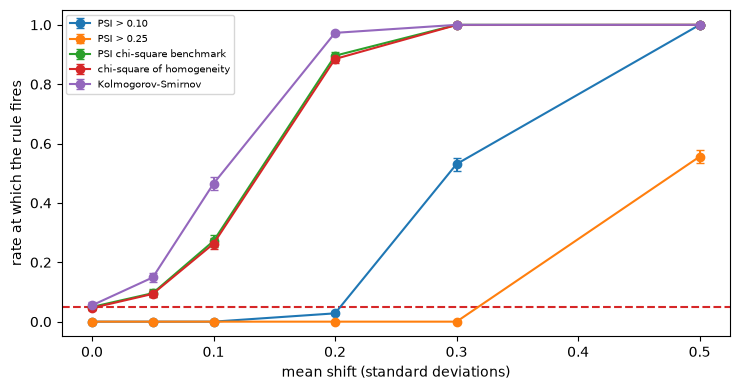

In [7]:
# Print the firing rate of each rule and test along the ladder (samples of 1000) and draw the curves with Wilson intervals
curves = {
    "PSI > 0.10": ("stability.psi", "metric>0.1"), "PSI > 0.25": ("stability.psi", "metric>0.25"),
    "PSI chi-square benchmark": ("stability.psi", "p<0.05"),
    "chi-square of homogeneity": ("stability.chi2", "p<0.05"), "Kolmogorov-Smirnov": ("stability.ks", "p<0.05"),
}
print(f"{'shift':>7s} {'population PSI':>15s} " + " ".join(f"{name[:14]:>15s}" for name in curves))
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, (test, rule) in curves.items():
    cells = [rows[f"{test}@s{s:g}"]["rates"][rule] for s in ladder]
    rate = np.array([c["rate"] for c in cells])
    low = np.array([c["wilson_low"] for c in cells])
    high = np.array([c["wilson_high"] for c in cells])
    ax.errorbar(ladder, rate, yerr=[rate - low, high - rate], fmt="o-", capsize=3, label=name)
for s in ladder:
    psi_pop = TwoSample(1000, 1000, shift=s).truth()["population_psi"]
    print(f"{s:7.2f} {psi_pop:15.4f} " + " ".join(f"{rows[f'{t}@s{s:g}']['rates'][r]['rate']:15.3f}" for t, r in curves.values()))
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel(out["ladder"]["label"][LANG])
ax.set_ylabel("rate at which the rule fires")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

### Step 6: Yurdakul and Naranjo's Table 4, cell by cell

The paper's Table 4 gives the rate at which the two rules of thumb and the chi-square benchmark fire for six pairs of sample sizes and three shifts (0, a quarter and a half standard deviation), from 10,000 runs. The artifact keeps the 54 cells with the published and the measured rate. The next cell recomputes every standardised difference with the engine's `agrees_with_published`, counts the agreements, and prints the cells that disagree and the average difference over the cells strictly between 0 and 1.

In [8]:
# Recompute the standardised difference of every cell of Table 4, count the agreements and list the misses
from functools import reduce

from riskvalidation.harness import Rate, agrees_with_published

GLOSSARY = ()
gloss = lambda text: reduce(lambda acc, pair: acc.replace(*pair), GLOSSARY, text)

n_runs = golden["runs"]
agree, inside, misses = 0, [], []
for cell in golden["cells"]:
    ok, z = agrees_with_published(Rate(round(cell["measured"] * n_runs), n_runs), cell["published"], golden["runs_published"])
    agree += ok
    if 0 < cell["published"] < 1:
        inside.append(z)
    if not ok:
        misses.append((cell, z))
print("cells that agree:", agree, "of", len(golden["cells"]), "|", "committed:", golden["agree"], "|", "mean z, cells strictly between 0 and 1:", round(float(np.mean(inside)), 3))
for cell, z in misses:
    print(f"  {gloss(cell['row']):13s} {gloss(cell['column']):28s} published {cell['published']:.3f} | measured {cell['measured']:.4f} | z {z:+.2f}")
print("every miss is measured above the print:", all(c["measured"] > c["published"] for c, _ in misses))

cells that agree: 50 of 54 | committed: 50 | mean z, cells strictly between 0 and 1: 0.649
  m 100, n 400  shift 0.25 SD, PSI > 0.10    published 0.834 | measured 0.8522 | z +3.54
  m 100, n 400  shift 0.5 SD, PSI > 0.25     published 0.787 | measured 0.8098 | z +4.02
  m 200, n 200  shift 0 SD, chi-square       published 0.057 | measured 0.0688 | z +3.44
  m 200, n 400  shift 0.5 SD, PSI > 0.25     published 0.720 | measured 0.7421 | z +3.52
every miss is measured above the print: True


The next cell prints the first column group of the table, the cells with no shift, where the paper says the type I error of the 0.10 rule is too large unless both samples exceed 400, and where the chi-square benchmark stays near its level.

In [9]:
# Print the published and measured rates of Table 4 for the cells with no shift
print(f"{'samples':14s} {'PSI > 0.10':>20s} {'PSI > 0.25':>20s} {'chi-square benchmark':>24s}   (published / measured)")
for row_name in ("m 100, n 100", "m 100, n 200", "m 100, n 400", "m 200, n 200", "m 200, n 400", "m 400, n 400"):
    cells = {c["column"]: c for c in golden["cells"] if c["row"] == row_name}
    parts = []
    for column in ("shift 0 SD, PSI > 0.10", "shift 0 SD, PSI > 0.25", "shift 0 SD, chi-square"):
        c = cells[column]
        parts.append(f"{c['published']:.3f} / {c['measured']:.4f}")
    print(f"{row_name:14s} {parts[0]:>20s} {parts[1]:>20s} {parts[2]:>24s}")

samples                  PSI > 0.10           PSI > 0.25     chi-square benchmark   (published / measured)
m 100, n 100         0.849 / 0.8525       0.233 / 0.2284           0.076 / 0.0753
m 100, n 200         0.691 / 0.6959       0.074 / 0.0733           0.069 / 0.0669
m 100, n 400         0.560 / 0.5668       0.029 / 0.0296           0.066 / 0.0678
m 200, n 200         0.369 / 0.3807       0.004 / 0.0043           0.057 / 0.0688
m 200, n 400         0.160 / 0.1599       0.000 / 0.0005           0.060 / 0.0575
m 400, n 400         0.020 / 0.0186       0.000 / 0.0000           0.051 / 0.0555


### Step 7: drift is not miscalibration

The `calibration` panel shifts the covariates of a logistic portfolio by the same amounts while the model keeps its true coefficients, so its PDs stay right for every obligor. A drift alarm and a calibration test then answer different questions: the population moved, and the model is still right. The next cell prints the rate at which Hosmer-Lemeshow and Spiegelhalter reject along the ladder, with the artifact's finding on it.

In [10]:
# Print the rejection rate of Hosmer-Lemeshow and Spiegelhalter under a covariate shift with a right model
print(f"{'shift':>7s} {'Hosmer-Lemeshow':>17s} {'Spiegelhalter':>15s}")
for s in ladder:
    hl = rows[f"pd.hosmer_lemeshow@s{s:g}"]["rates"]["p<0.05"]["rate"]
    sp = rows[f"pd.spiegelhalter@s{s:g}"]["rates"]["p<0.05"]["rate"]
    print(f"{s:7.2f} {hl:17.4f} {sp:15.4f}")
finding = next(f for f in drift["findings"] if f["id"] == "F-DRIFT-NOT-MISCAL")
status_name = {"accepted": "accepted", "closed": "closed", "open": "open"}
print(finding["id"], finding["severity"], status_name[finding["status"]], "|", finding["title"][LANG])

  shift   Hosmer-Lemeshow   Spiegelhalter
   0.00            0.0510          0.0540
   0.05            0.0560          0.0560
   0.10            0.0580          0.0540
   0.20            0.0585          0.0525
   0.30            0.0530          0.0560
   0.50            0.0485          0.0500
F-DRIFT-NOT-MISCAL S4 accepted | Drift is not miscalibration: a right model stays calibrated under a covariate shift, so stability alarms and calibration tests answer different questions


## Results

- **The PSI has a noise floor that depends only on the sample sizes.** With ten bins, the expected PSI when nothing changes is 0.180 for two samples of 100, 0.090 for 200, 0.045 for 400 and 0.018 for 1,000. The 5% benchmark is 0.338, 0.169, 0.085 and 0.034. A fixed 0.10 band sits below the noise floor at 100 observations, about at it at 200 and far above it at 1,000, so it cannot mean the same thing at two sample sizes. The two rules equal the 5% benchmark at 338 and at 135 observations per sample.
- **The band and the test can disagree in both directions.** Two samples of 100 with no change gave a PSI of 0.280, "significant change" by the band, with a p-value of 0.12 and a benchmark of 0.338. Two samples of 1,000 shifted by 0.2 standard deviations gave a PSI of 0.039, "little change" by the band, above the benchmark of 0.034 with a p-value of 0.021. One dataset each is an illustration, not a rate; the rates follow.
- **The false-alarm rate of the 0.10 rule is 85.7% with samples of 100.** It is 37.9% at 200 and 2.1% at 400, and 0% at 1,000. The 0.25 rule fires 22.7% of the time at 100 observations and almost never above 200. The replay of the committed row gives exactly its counts (279, 3,399 and 914). The chi-square benchmark stays between 4.9% and 7.5%, closest to 5% as the samples grow, with a mild excess at small samples that Yurdakul and Naranjo's Table 4 also shows.
- **Fixed bands lose power as the samples grow.** With 1,000 per sample and a shift of 0.1 standard deviations the benchmark fires 27.2% of the time, the chi-square of homogeneity 26.3%, Kolmogorov-Smirnov 46.5% and the two rules of thumb never. At 0.2 the benchmark fires 89.6% and Kolmogorov-Smirnov 97.3%, while the 0.10 rule fires 2.8% and the 0.25 rule never. The 0.25 rule needs a shift of 0.5 and then fires 55.6% of the time. The population PSI explains it: 0.0096 at 0.1, 0.0383 at 0.2, 0.2377 at 0.5, well under the 0.10 and 0.25 bands for the shifts a benchmark can see.
- **Table 4 reproduces in 50 of 54 cells, with a stated offset.** The four cells that differ are all measured above the print, with standardised differences from 3.44 to 4.02; the mean over the cells strictly between 0 and 1 is +0.649. The artifact's note says no treatment of empty bins explains the offset because the paper does not state its own, and that every qualitative finding of the paper reproduces, as the shift-0 columns show: the 0.10 rule is far above its level at small samples, the 0.25 rule collapses above 200 and the benchmark stays near 5%.
- **Drift is not miscalibration.** With every covariate shifted by up to half a standard deviation and the model exactly right, Hosmer-Lemeshow rejects between 4.85% and 5.85% and Spiegelhalter between 5.0% and 5.6%, at their level throughout. A stability alarm says the population moved; whether the PDs are still right is a question for the calibration tests, and a validator should raise the two alarms separately.

What this notebook does not show: the PSI with bins taken from the development sample's own quantiles, drift in a variable that is not normal, or the choice of ten bins; each changes the constants but not the argument. The shifts are a design choice of Contraste, and power against them is not a probability of detecting drift in a real portfolio.

## Summary

- The PSI has a noise floor of $(1/n + 1/m)(B-1)$ that depends only on the sample sizes, and a 5% benchmark $(1/n + 1/m)\chi^2_{0.95,\,B-1}$ that follows it; a fixed band cannot.
- The 0.10 rule fires in 85.7% of samples of 100 when nothing changed, and the 0.25 rule in 22.7%; with 1,000 per sample both are nearly silent on shifts the benchmark detects 27% to 90% of the time.
- Kolmogorov-Smirnov was the most powerful drift test measured here, and the chi-square of homogeneity matches the PSI benchmark.
- Yurdakul and Naranjo's Table 4 reproduces in 50 of 54 cells, the four misses all above the print, with a stated offset of 0.65 standard errors on average.
- Drift is not miscalibration: a right model stays at its size under a covariate shift, so the two alarms answer different questions.

**What to try next.** Replay the n = 100 row with the `binning="sample"` option of `TwoSample` (bins taken from the development sample's own quantiles) and compare its false-alarm rate with the fixed-bin one; then read notebook 06.

## References

- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4): the rules of thumb, Theorem 3.3, the benchmark and Table 4. https://doi.org/10.21314/JRMV.2020.227
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.